# Gaussian beams and paraxial ray optics

Worked examples using `beamprop`:

1. free-space expansion of a Nd:YAG beam,
2. focusing with a thin lens, checking the q-parameter method against Self's lens equation,
3. a two-lens beam expander,
4. the stability diagram of a two-mirror laser resonator.

In [1]:
import sys, math
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import beamprop as bp

lam = 1064e-9   # m

## 1. Free-space propagation

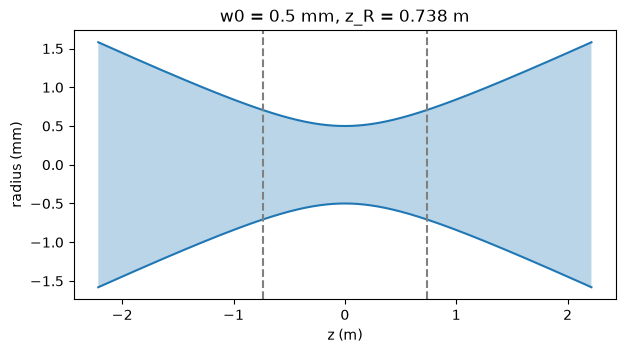

In [2]:
w0 = 0.5e-3
zr = bp.rayleigh_range(w0, lam)
z = np.linspace(-3 * zr, 3 * zr, 400)
w = bp.beam_radius(z, w0, lam)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.fill_between(z, -w * 1e3, w * 1e3, alpha=0.3)
ax.plot(z, w * 1e3, "C0"); ax.plot(z, -w * 1e3, "C0")
for s in (-zr, zr):
    ax.axvline(s, ls="--", c="gray")
ax.set(xlabel="z (m)", ylabel="radius (mm)", title=f"w0 = {w0*1e3} mm, z_R = {zr:.3f} m")
plt.show()

## 2. Focusing with a thin lens

The same beam meets a 100 mm lens placed 0.5 m after its waist. The q-parameter result and the closed-form expression should agree.

In [3]:
f, s = 0.1, 0.5
beam_after = bp.GaussianBeam.from_waist(w0, lam, z=s).propagate(bp.thin_lens(f))
w_self, s_self = bp.focus_by_thin_lens(w0, lam, f, s)
print(f"q-parameter : waist {beam_after.waist*1e6:.3f} um at {beam_after.distance_to_waist*1e3:.3f} mm")
print(f"Self (1983) : waist {w_self*1e6:.3f} um at {s_self*1e3:.3f} mm")

q-parameter : waist 59.554 um at 105.675 mm
Self (1983) : waist 59.554 um at 105.675 mm


## 3. A 5x Keplerian beam expander

The lens spacing is the sum of the focal lengths. Tracing two rays confirms the angular magnification of $-f_2/f_1$.

system matrix:
 [[-5.    0.24]
 [ 0.   -0.2 ]]
ray (1 mm, 0) -> (-0.005000000000000001, 3.552713678800501e-18)
ray (0, 1 mrad) -> (0.00024000000000000003, -0.00020000000000000017)


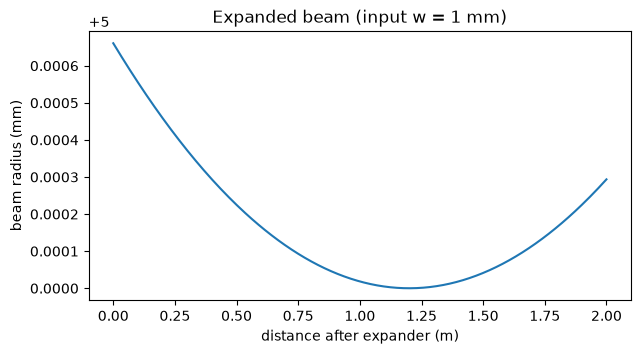

In [4]:
f1, f2 = 0.04, 0.2
M = bp.system(bp.thin_lens(f1), bp.free_space(f1 + f2), bp.thin_lens(f2))
print("system matrix:\n", np.round(M, 6))
print("ray (1 mm, 0) ->", bp.trace(M, 1e-3, 0.0))
print("ray (0, 1 mrad) ->", bp.trace(M, 0.0, 1e-3))

beam = bp.GaussianBeam.from_waist(1e-3, lam)
zs = np.linspace(0, 2, 300)
sizes = []
for zz in zs:
    sizes.append(beam.propagate(bp.system(M, bp.free_space(zz))).w)
plt.figure(figsize=(7, 3.5))
plt.plot(zs, np.array(sizes) * 1e3)
plt.xlabel("distance after expander (m)"); plt.ylabel("beam radius (mm)")
plt.title("Expanded beam (input w = 1 mm)")
plt.show()

## 4. Resonator stability diagram

A two-mirror cavity is stable when $0 \le g_1 g_2 \le 1$, where $g_i = 1 - L/R_i$.

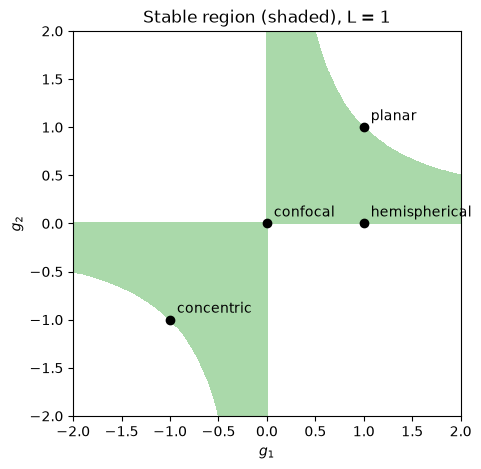

plano-concave cavity L=0.3 m, R=1.0 m: TEM00 waist = 394.0 um


In [5]:
g = np.linspace(-2, 2, 401)
G1, G2 = np.meshgrid(g, g)
stable = (G1 * G2 >= 0) & (G1 * G2 <= 1)

fig, ax = plt.subplots(figsize=(5, 5))
ax.contourf(G1, G2, stable, levels=[0.5, 1.5], colors=["C2"], alpha=0.4)
examples = {"planar": (math.inf, math.inf), "confocal": (1.0, 1.0),
            "concentric": (0.5, 0.5), "hemispherical": (math.inf, 1.0)}
for name, (R1, R2) in examples.items():
    g1, g2 = bp.resonator_g(1.0, R1, R2)
    ax.plot(g1, g2, "ko"); ax.annotate(name, (g1, g2), textcoords="offset points", xytext=(5, 5))
ax.set(xlabel="$g_1$", ylabel="$g_2$", title="Stable region (shaded), L = 1")
plt.show()

L, R = 0.3, 1.0
print(f"plano-concave cavity L={L} m, R={R} m: TEM00 waist = {bp.resonator_mode(L, math.inf, R, lam)*1e6:.1f} um")